# EEE4022S Thesis Project: The development of a low-cost X-ray phantom for bone suppression and radiography system calibration

## By: M Saeed Solomon (SLMMOG032)

This notebook is the initial experimental version of the pipeline to enable easier tuning and visualisation of different parts of the code.

**Note on data:** no real Lodox DICOM acquisitions are checked into this repo yet. Phase 1 looks for `images/1.dcm` (low kVp) and `images/2.dcm` (high kVp); if they're not found it falls back to a physically-modelled synthetic phantom pair (`pipeline/synthetic.py`) so every phase below can still run end-to-end. Swap in real acquisitions by adding those two files to `images/`.

In [1]:
# Prephase: importing all libraries
# This is done here at the beginning to ensure all libraries are installed prior to running the pipeline.

import os

import matplotlib.pyplot as plt
import numpy as np

from pipeline import load, align, subtract, metrics, benchmark, output, synthetic

images/1.dcm/images/2.dcm not found -- using synthetic phantom pair for this run.


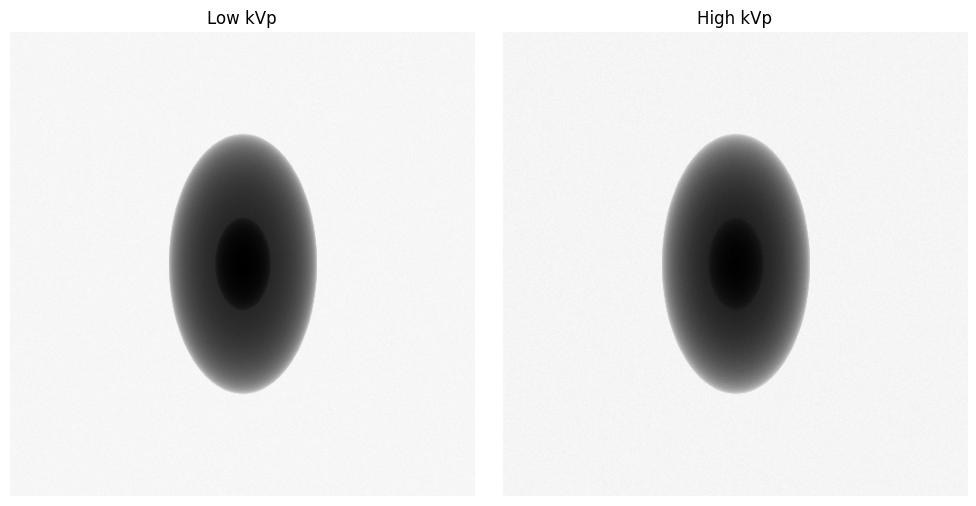

In [2]:
"""========================================================================================================="""
# Phase 1: Importing images

LOW_PATH = "images/1.dcm"
HIGH_PATH = "images/2.dcm"

if os.path.exists(LOW_PATH) and os.path.exists(HIGH_PATH):
    USING_SYNTHETIC_DATA = False
    image_1, image_2, ds_1, ds_2 = load.load_dicom_pair(LOW_PATH, HIGH_PATH)
    print(f"Loaded real DICOM pair from {LOW_PATH}, {HIGH_PATH}")
else:
    USING_SYNTHETIC_DATA = True
    phantom = synthetic.generate_synthetic_phantom_pair()
    image_1, image_2 = phantom["low"], phantom["high"]
    print(f"{LOW_PATH}/{HIGH_PATH} not found -- using synthetic phantom pair for this run.")

# Display initial images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image_1, cmap="gray")
axes[0].set_title("Low kVp")
axes[1].imshow(image_2, cmap="gray")
axes[1].set_title("High kVp")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

(synthetic run) injected a (2.3, -1.7) px shift into the high-kVp image to exercise registration.


Estimated shift (dy, dx): [-2.2  1.8]
Registration applied: True


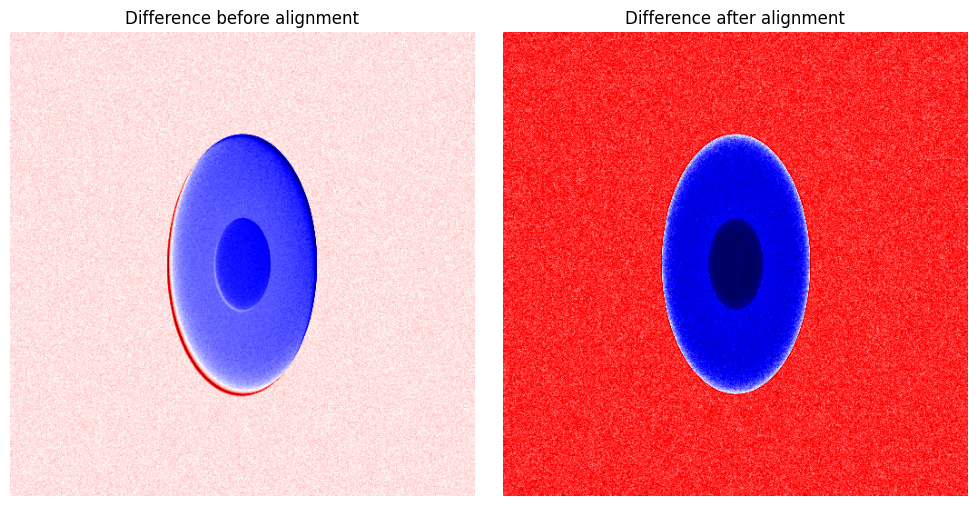

In [3]:
"""========================================================================================================="""
# Phase 2: Preprocessing images
# Sequential (not simultaneous) acquisition means the low/high kVp exposures may be offset by subject or
# detector motion between shots. Check for and correct any misalignment rather than assuming it away.

if USING_SYNTHETIC_DATA:
    # The synthetic pair above has zero motion between exposures by construction, which wouldn't exercise
    # this phase at all. Inject a small sub-pixel/pixel shift here purely to prove the registration step
    # actually detects and corrects motion when it's present (a real static-phantom scan should need little
    # to no correction, but this must be verified per-acquisition, not assumed).
    from scipy.ndimage import shift as _ndi_shift
    image_2 = _ndi_shift(image_2, shift=(2.3, -1.7), order=1, mode="nearest")
    print("(synthetic run) injected a (2.3, -1.7) px shift into the high-kVp image to exercise registration.")

align_result = align.align_pair(image_1, image_2)
image_2_aligned = align_result["aligned"]

print(f"Estimated shift (dy, dx): {align_result['shift']}")
print(f"Registration applied: {align_result['registration_applied']}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image_1 - image_2, cmap="seismic")
axes[0].set_title("Difference before alignment")
axes[1].imshow(image_1 - image_2_aligned, cmap="seismic")
axes[1].set_title("Difference after alignment")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Bone-cancelling weight: 2.0005


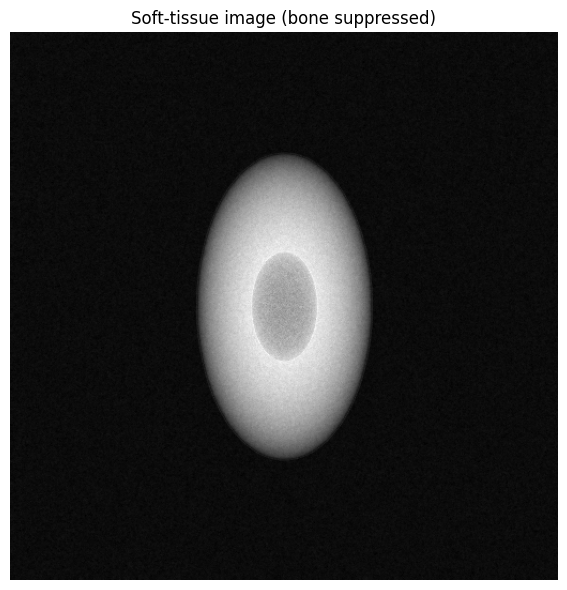

In [4]:
"""========================================================================================================="""
# Phase 3: Bone Suppression
# Weighted log-subtraction (SS3): S = log(I_low) - w * log(I_high), with w chosen to cancel bone signal.
# w is calibrated from a bone step-wedge scan (Brody et al. 1981), NOT fit directly on an anatomical ROI --
# soft-tissue thickness also varies across the bone core in the phantom (and in real anatomy), which would
# confound a variance-minimisation fit done there. The step-wedge holds the soft-tissue background constant.

if USING_SYNTHETIC_DATA:
    bone_center = phantom["bone_center"]
    bone_semi_axes = phantom["bone_semi_axes"]
    tissue_semi_axes = phantom["tissue_semi_axes"]

    stepwedge = synthetic.generate_bone_stepwedge(coeffs=phantom["coeffs"])
    bone_cancelling_weight = subtract.estimate_weight_from_stepwedge(
        stepwedge["low"], stepwedge["high"], stepwedge["step_mask"]
    )
else:
    # TODO: replace with the real phantom's bone-core geometry (pixel coordinates) once known.
    bone_center = (image_1.shape[0] / 2, image_1.shape[1] / 2)
    bone_semi_axes = (image_1.shape[0] * 0.10, image_1.shape[1] * 0.06)
    tissue_semi_axes = (image_1.shape[0] * 0.28, image_1.shape[1] * 0.16)
    # TODO: replace with a weight calibrated from a real bone step-wedge scan
    # (subtract.estimate_weight_from_stepwedge) once one has been acquired.
    bone_cancelling_weight = 1.0

bone_mask = metrics.elliptical_mask(image_1.shape, bone_center, bone_semi_axes)

suppression = subtract.suppress_bone(image_1, image_2_aligned, weight=bone_cancelling_weight)
soft_tissue_image = suppression["soft_tissue_image"]

print(f"Bone-cancelling weight: {bone_cancelling_weight:.4f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(soft_tissue_image, cmap="gray")
ax.set_title("Soft-tissue image (bone suppressed)")
ax.axis("off")
plt.tight_layout()
plt.show()

# Note: a shadow tracing the phantom's outline can remain even with an exactly-correct weight -- this is
# NOT residual bone signal (with w = mu_bone_low / mu_bone_high the bone term cancels algebraically, and a
# no-bone control image shows almost the same shadow). It's mostly the natural centre-to-edge thickness
# falloff of a rounded soft-tissue object in projection (thicker through the middle -> more attenuation
# there), only slightly offset by bone displacing some of that tissue. Expect this smooth geometric shading
# to survive bone suppression in real rounded-limb images too -- a real lesion would show as a localised
# bump on top of this taper, not the taper itself.

Benchmark CNR/SNR (synthetic stand-in -- replace with real dataset for the thesis result):
  original: SNR=56.005, CNR=38.893
  suppressed: SNR=55.559, CNR=10.402


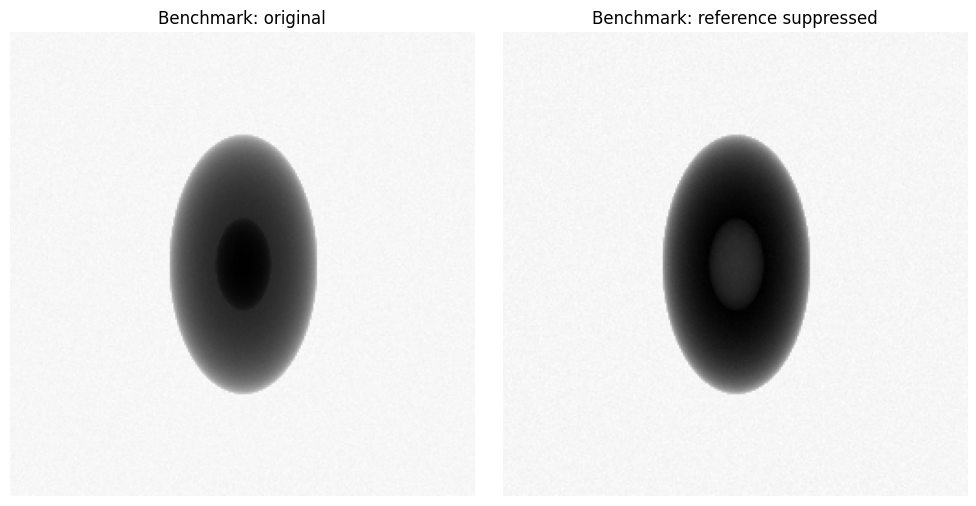

In [5]:
"""========================================================================================================="""
# Phase 4: Open-source imaging
# Sanity-check the CNR/SNR metrics on reference data independent of the custom phantom. Real benchmark
# datasets (JSRT + BSE-JSRT, IEEE DataPort, NIH ChestX-ray14/RSNA, BS-LDM, hand/forearm atlases) require
# external download/registration -- point `load.load_image_pair_generic` at them once available. Until
# then this uses a synthetic stand-in purely to exercise the loader/metric code path.

benchmark_pair = synthetic.generate_synthetic_benchmark_pair()

benchmark_results = benchmark.evaluate_benchmark_pair(
    benchmark_pair["original"],
    benchmark_pair["reference_suppressed"],
    benchmark_pair["bone_center"],
    benchmark_pair["bone_semi_axes"],
    benchmark_pair["tissue_semi_axes"],
)

print("Benchmark CNR/SNR (synthetic stand-in -- replace with real dataset for the thesis result):")
for stage, vals in benchmark_results.items():
    print(f"  {stage}: SNR={vals['snr']:.3f}, CNR={vals['cnr']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(benchmark_pair["original"], cmap="gray")
axes[0].set_title("Benchmark: original")
axes[1].imshow(benchmark_pair["reference_suppressed"], cmap="gray")
axes[1].set_title("Benchmark: reference suppressed")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
"""========================================================================================================="""
# Phase 5: CNR/SNR Validation
# Measure CNR/SNR on the pipeline output using ROIs tied to the phantom's known material zones, and
# compare against the theoretical contrast predicted from the phantom's attenuation coefficients.

tissue_mask = metrics.annulus_mask(image_1.shape, bone_center, bone_semi_axes, tissue_semi_axes)
background_mask = ~metrics.elliptical_mask(image_1.shape, bone_center, tissue_semi_axes)

measured_snr = metrics.snr(soft_tissue_image[tissue_mask], soft_tissue_image[background_mask])
measured_cnr = metrics.cnr(
    soft_tissue_image[bone_mask], soft_tissue_image[tissue_mask], soft_tissue_image[background_mask]
)

phase5_results = {"snr": measured_snr, "cnr": measured_cnr}

if USING_SYNTHETIC_DATA:
    # Known ground-truth thicknesses at the bone-core centre, for a theoretical comparison.
    thickness_bone = float(phantom["t_bone"][round(bone_center[0]), round(bone_center[1])])
    thickness_soft = float(phantom["t_soft"][round(bone_center[0]), round(bone_center[1]) + int(bone_semi_axes[1]) + 5])
    theoretical = metrics.theoretical_contrast(
        phantom["coeffs"], bone_cancelling_weight, thickness_bone, thickness_soft
    )
    phase5_results["theoretical_contrast"] = theoretical
    print(f"Measured CNR:     {measured_cnr:.4f}")
    print(f"Theoretical contrast (noise-free): {theoretical:.4f}")
    print("(Measured CNR includes noise in the denominator, so it is not directly equal to the\n"
          " theoretical noise-free contrast above -- the theoretical value validates the *signal* term.)")
else:
    print("Theoretical comparison requires the phantom's known attenuation coefficients and material\n"
          "thicknesses -- add these once the real phantom's material properties are characterised.")

print(f"Measured SNR (soft-tissue region): {measured_snr:.4f}")
print(f"Measured CNR (bone vs soft-tissue): {measured_cnr:.4f}")

Measured CNR:     7.7157
Theoretical contrast (noise-free): 0.7235
(Measured CNR includes noise in the denominator, so it is not directly equal to the
 theoretical noise-free contrast above -- the theoretical value validates the *signal* term.)
Measured SNR (soft-tissue region): 50.8592
Measured CNR (bone vs soft-tissue): 7.7157


In [7]:
"""========================================================================================================="""
# Phase 6: Final Output

os.makedirs("outputs", exist_ok=True)
output.save_image_png(soft_tissue_image, "outputs/soft_tissue_image.png")

summary_report = output.build_summary_report({
    "phase5_phantom": phase5_results,
    "phase4_benchmark": benchmark_results,
})
output.save_report_csv(summary_report, "outputs/summary_report.csv")

print("Saved outputs/soft_tissue_image.png and outputs/summary_report.csv")
summary_report

Saved outputs/soft_tissue_image.png and outputs/summary_report.csv


,stage,snr,cnr,theoretical_contrast
0,phase5_phantom,50.859155,7.715714,0.723479
1,phase4_benchmark.original,56.005162,38.892590,NaN
2,phase4_benchmark.suppressed,55.559112,10.401711,NaN
